# When the blur is slower than the flow: clipped and corrected samplers on the critically damped Langevin flow

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/neginyan/cld-corrected-sampler/blob/main/demo/cld_corrected_sampler_demo.ipynb)

Demo for the paper by Taishi Namba (code: [github.com/neginyan/cld-corrected-sampler](https://github.com/neginyan/cld-corrected-sampler)).

**The setting.** The critically damped Langevin (CLD) flow moves position $x$ and velocity $v$ together. Here we combine it with an *isotropic* noise schedule specified by its marginals, a blur of width $\sigma(t)=\sigma_{\min}e^{rt}$. The standard CLD gives its noise by an SDE and never meets the issue shown here.

**The point.** If the blur widens more slowly than the flow stretches ($r<\kappa$), the standard reverse SDE with its negative noise clipped, sampler **(i)**, pulls samples towards the mode centres. The **corrected** sampler **(ii)** differs by one line and stays exact, with no retraining.

The demo uses the exact score of an 8-mode Gaussian mixture and setting C of the paper (CLD mass $M=10$, $\sigma_{\min}=s/2$), where the effect is large. Everything runs on a CPU in a few minutes.

In [1]:
import numpy as np, os, sys, time, hashlib, difflib, subprocess
from scipy.linalg import expm
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# ---- CLD flow, setting C of the paper: mass M = 10, critical damping Gamma = 2 sqrt(M), beta chosen so that kappa = 2
M_MASS = 10.0
b1 = np.array([[0.0, 1 / M_MASS], [-1.0, -2 * np.sqrt(M_MASS) / M_MASS]])
BETA = 2.0 / np.linalg.eigvalsh((b1 + b1.T) / 2).max()
B = np.kron(np.eye(2), BETA * b1)                       # phase space z = (x1, v1, x2, v2)
SYM = (B + B.T) / 2
W, V = np.linalg.eigh(SYM)
KAPPA = W.max()                                         # largest stretching rate of the flow
print(f'kappa = {KAPPA:.3f}')

# ---- data: 8 Gaussian modes on the unit circle (position std s = 0.08), CLD initial velocities N(0, 0.01)
S_POS = 0.08
SMIN, SMAX = 0.5 * S_POS, 40.0                          # blur at the end and at the start of sampling
ang = 2 * np.pi * np.arange(8) / 8
MU = np.zeros((8, 4)); MU[:, 0] = np.cos(ang); MU[:, 2] = np.sin(ang)
S0 = np.diag([S_POS**2, 0.01, S_POS**2, 0.01])
POS = [0, 2]
TARGET_VAR = S_POS**2 + SMIN**2                         # within-mode position variance of the data blurred by sigma_min

def exact_score(z, t, r):
    """Exact score of the forward marginal: mixture of N(e^{Bt} mu_k, e^{Bt} S0 e^{Bt}^T + sigma^2 I)."""
    Mt = expm(B * t); C = Mt @ S0 @ Mt.T + (SMIN * np.exp(r * t))**2 * np.eye(4); P = np.linalg.inv(C)
    m = MU @ Mt.T; Pz, Pm = z @ P, m @ P
    logit = Pz @ m.T - 0.5 * (m * Pm).sum(1)[None]
    logit -= logit.max(1, keepdims=True); w = np.exp(logit); w /= w.sum(1, keepdims=True)
    return -(Pz - w @ Pm)

kappa = 2.000


## The one-line difference

Both samplers integrate the same reverse-time equation from $t=T$ to $0$, with the same noise $\sqrt{G_+}$. Here $G=2\sigma^2(rI-\mathrm{Sym}\,B)$ is the noise the schedule requires, and $G_+$ is $G$ with its negative eigenvalues set to zero. Only the drift differs:

In [2]:
CLIPPED = """def drift(z, s, G, G_plus):
    return z @ B.T - s @ G_plus.T
"""
CORRECTED = """def drift(z, s, G, G_plus):
    return z @ B.T - s @ (0.5 * (G + G_plus)).T
"""
print(''.join(difflib.unified_diff(CLIPPED.splitlines(True), CORRECTED.splitlines(True), '(i) clipped', '(ii) corrected')))
DRIFT = {}
for name, src in [('clipped', CLIPPED), ('corrected', CORRECTED)]:
    ns = {'B': B}; exec(src, ns); DRIFT[name] = ns['drift']      # the functions used below are exactly these strings

--- (i) clipped
+++ (ii) corrected
@@ -1,2 +1,2 @@
 def drift(z, s, G, G_plus):
-    return z @ B.T - s @ G_plus.T
+    return z @ B.T - s @ (0.5 * (G + G_plus)).T



## Run both samplers (exact score, paired noise)

The two samplers start from the same exact sample of $p_T$ and use the same Brownian increments. Euler–Maruyama is used with step $h=0.002$. At this step, the corrected sampler is 1–5% too wide from discretization alone; this vanishes as $h\to0$.

In [3]:
def sample(rk, kind, N=4000, h=0.002, seed=0):
    r = rk * KAPPA; T = np.log(SMAX / SMIN) / r; K = int(np.ceil(T / h)); ts = np.linspace(T, 0.0, K + 1)
    rng0, rng = np.random.default_rng(100 + seed), np.random.default_rng(200 + seed)
    k = rng0.integers(0, 8, N)
    z = MU[k] + rng0.standard_normal((N, 4)) @ np.linalg.cholesky(S0).T
    z = z @ expm(B * T).T + SMAX * rng0.standard_normal((N, 4))           # exact sample of p_T
    for i in range(K):
        t, dt = ts[i], ts[i] - ts[i + 1]
        sig2 = (SMIN * np.exp(r * t))**2
        G = 2 * sig2 * (r * np.eye(4) - SYM)
        lam = np.clip(r - W, 0, None)
        G_plus = 2 * sig2 * (V * lam) @ V.T
        sqrt_G_plus = np.sqrt(2 * sig2) * (V * np.sqrt(lam)) @ V.T
        z = z - dt * DRIFT[kind](z, exact_score(z, t, r), G, G_plus) + np.sqrt(dt) * rng.standard_normal(z.shape) @ sqrt_G_plus.T
    return z

def within_mode(z):
    """Distance from the nearest mode centre (positions only), in units of the target std, and the variance ratio."""
    x = z[:, POS]; d2 = ((x[:, None, :] - MU[None][:, :, POS])**2).sum(-1); d = np.sqrt(d2.min(1))
    return d / np.sqrt(TARGET_VAR), (d**2).mean() / 2 / TARGET_VAR

def theory_L(rk):
    """One-mode Gaussian theory of the paper, Eq. (4): dE/dtau = A E + E A^T - G_-, A = -B - G_+ C^-1, E(0) = 0."""
    r = rk * KAPPA; T = np.log(SMAX / SMIN) / r
    if r >= KAPPA: return 0.0
    def rhs(tau, y):
        t = T - tau; E = y.reshape(4, 4); Mt = expm(B * t); sig2 = (SMIN * np.exp(r * t))**2
        C = Mt @ S0 @ Mt.T + sig2 * np.eye(4)
        Gp = 2 * sig2 * (V * np.clip(r - W, 0, None)) @ V.T; Gm = 2 * sig2 * (V * np.clip(W - r, 0, None)) @ V.T
        A = -B - Gp @ np.linalg.inv(C)
        return (A @ E + E @ A.T - Gm).ravel()
    E = solve_ivp(rhs, [0, T], np.zeros(16), method='DOP853', rtol=1e-9, atol=1e-14).y[:, -1].reshape(4, 4)
    return float(np.log((TARGET_VAR + E[0, 0]) / TARGET_VAR))

RKS = [0.25, 0.5, 0.75, 1.0, 1.25]
RESULTS = {}
t0 = time.time()
for rk in RKS:
    zi, zii = sample(rk, 'clipped'), sample(rk, 'corrected')
    RESULTS[rk] = {'i': within_mode(zi), 'ii': within_mode(zii), 'theory': theory_L(rk)}
    R = RESULTS[rk]
    print(f"r/kappa = {rk:4.2f}:  variance (i) {R['i'][1]:.3f}   (ii) {R['ii'][1]:.3f}   (target 1)   "
          f"paired ratio (i)/(ii) {R['i'][1] / R['ii'][1]:.3f}   theory {np.exp(R['theory']):.3f}")
print(f'({time.time() - t0:.0f} s)  The paired ratio cancels sampling noise and the ~1% discretization error shared by (i) and (ii).')

r/kappa = 0.25:  variance (i) 0.770   (ii) 0.994   (target 1)   paired ratio (i)/(ii) 0.775   theory 0.776
r/kappa = 0.50:  variance (i) 0.832   (ii) 1.013   (target 1)   paired ratio (i)/(ii) 0.821   theory 0.812
r/kappa = 0.75:  variance (i) 0.894   (ii) 1.020   (target 1)   paired ratio (i)/(ii) 0.877   theory 0.880
r/kappa = 1.00:  variance (i) 1.048   (ii) 1.048   (target 1)   paired ratio (i)/(ii) 1.000   theory 1.000
r/kappa = 1.25:  variance (i) 1.001   (ii) 1.001   (target 1)   paired ratio (i)/(ii) 1.000   theory 1.000
(51 s)  The paired ratio cancels sampling noise and the ~1% discretization error shared by (i) and (ii).


## Distance from the mode centre

Below the threshold ($r/\kappa<1$), the clipped sampler (orange) is pulled towards the centres, and the one-mode theory (dashed orange) predicts by how much. The corrected sampler (blue) lies on the target (grey). At and above the threshold the two samplers are the same equation.

ipywidgets is not installed: showing every value of r/kappa below instead of a slider.


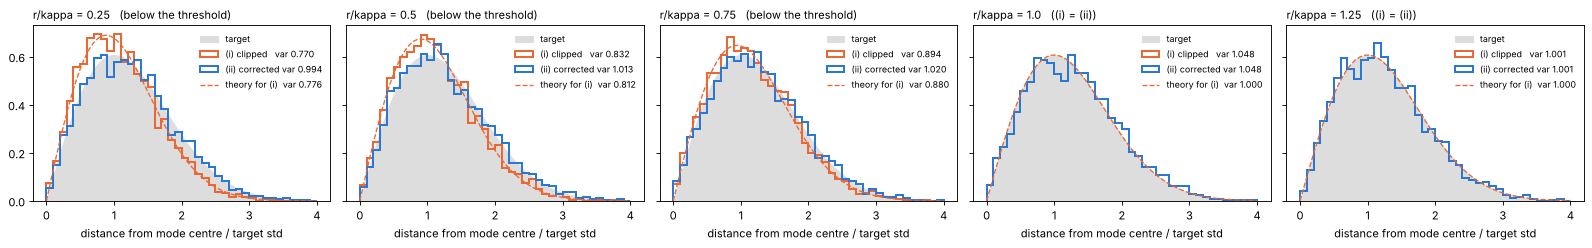

In [4]:
xs = np.linspace(0, 4, 200)
rayleigh = lambda x, a2: x / a2 * np.exp(-x**2 / (2 * a2))       # 2-D Gaussian radius, variance a2 per coordinate

def show(rk, ax=None):
    R = RESULTS[rk]; ax = ax or plt.figure(figsize=(5.2, 3.3)).gca(); bins = np.linspace(0, 4, 41)
    ax.fill_between(xs, rayleigh(xs, 1.0), color='#dddddd', label='target')
    ax.hist(R['i'][0], bins, density=True, histtype='step', lw=1.8, color='#eb6834', label=f"(i) clipped   var {R['i'][1]:.3f}")
    ax.hist(R['ii'][0], bins, density=True, histtype='step', lw=1.8, color='#2a78d6', label=f"(ii) corrected var {R['ii'][1]:.3f}")
    ax.plot(xs, rayleigh(xs, np.exp(R['theory'])), '--', color='#eb6834', lw=1.2, label=f"theory for (i)  var {np.exp(R['theory']):.3f}")
    ax.set_title(f'r/kappa = {rk}' + ('   (below the threshold)' if rk < 1 else '   ((i) = (ii))'), loc='left', fontsize=10)
    ax.set_xlabel('distance from mode centre / target std'); ax.legend(frameon=False, fontsize=8)

try:
    import ipywidgets as widgets
    widgets.interact(lambda rk: (show(rk), plt.show()), rk=widgets.SelectionSlider(options=RKS, value=0.25, description='r/kappa'))
except ImportError:
    print('ipywidgets is not installed: showing every value of r/kappa below instead of a slider.')

fig, axs = plt.subplots(1, len(RKS), figsize=(4.0 * len(RKS), 3.2), sharey=True)
for rk, ax in zip(RKS, axs): show(rk, ax)
plt.tight_layout(); plt.show()

To try another value, run `RESULTS[rk] = {...}` as in the loop above for that `rk` (10–30 s), then `show(rk)`.

## Optional: a learned score — the probability-flow ODE carries score errors, the corrected SDE forgets them

This part uses networks trained in the paper (setting B, CLD mass, $r/\kappa=0.3$). They are loaded from the repository (cloned if needed), and their SHA-256 hashes are checked against the values written in this notebook before use. We compare an early checkpoint (10k steps, larger score error) with the final network (300k steps). Both samplers are exact for the exact score; with a learned score, the ODE deviates much more than the corrected SDE (paper, Sec. VI).

In [5]:
EXPECTED_SHA256 = {
    'weights/learned_eps/B_seed1_step10000.npz':  'b83bb3e659a5b098cc6427b0dd546e89ecfc4780192e7ae8b42827480f6cb48f',
    'weights/learned_eps/B_seed1_step300000.npz': 'b6126f99c9f271e2f9f372644b9c2df4c38079d43d5f8714e74375b3fa7d275c'}
REPO = None
for cand in [os.path.abspath('..'), os.path.abspath('cld-corrected-sampler')]:
    if os.path.exists(os.path.join(cand, 'weights')) and os.path.exists(os.path.join(cand, 'src')): REPO = cand; break
if REPO is None:
    REPO = os.path.abspath('cld-corrected-sampler')
    subprocess.run(['git', 'clone', '--depth', '1', 'https://github.com/neginyan/cld-corrected-sampler', REPO], check=True)
sha = lambda p: hashlib.sha256(open(p, 'rb').read()).hexdigest()
for f, h in EXPECTED_SHA256.items():
    assert sha(os.path.join(REPO, f)) == h, f'SHA-256 mismatch for {f}'
    print('SHA-256 OK ', f)
sys.path.insert(0, os.path.join(REPO, 'src'))
from learned import setting, Precond, LearnedScore, new_net, train_data
from cld_mixture import mixture, sample_mixture, ExactScore, prior_exact, run_sampler, mode_stats

SHA-256 OK  weights/learned_eps/B_seed1_step10000.npz
SHA-256 OK  weights/learned_eps/B_seed1_step300000.npz


exact score             (ii) 1.004   (iii) 0.987
learned, 10k steps      (ii) 1.184   (iii) 11.625
learned, 300k steps     (ii) 0.999   (iii) 1.035
(280 s; within-mode variance relative to the target, 1 = correct; N = 2000, so about 3% sampling noise)


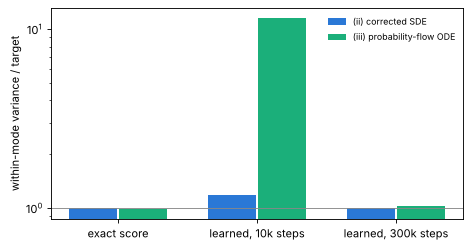

In [6]:
p = setting('B'); w, mu, S = mixture(); pc = Precond(p, train_data(0))
ref = mode_stats(sample_mixture(w, mu, S, 200000, np.random.default_rng(999), extra_var=p.s0**2)[0], mu)['within_var']
N, K = 2000, int(np.ceil(p.T / 0.002))
z0 = prior_exact(p, w, mu, S, N, np.random.default_rng(100))
def var_ratio(score, mode):
    z = run_sampler(score, p, z0, mode, K, np.random.default_rng(200))
    return mode_stats(z, mu)['within_var'] / ref
rows = {'exact score': ExactScore(p, w, mu, S)}
for step in [10000, 300000]:
    net = new_net(1); net.load(os.path.join(REPO, 'weights', 'learned_eps', f'B_seed1_step{step}'))
    rows[f'learned, {step // 1000}k steps'] = LearnedScore(net, pc)
t0 = time.time(); OUT = {}
for name, sc in rows.items():
    OUT[name] = {'(ii) corrected SDE': var_ratio(sc, 'fixed'), '(iii) probability-flow ODE': var_ratio(sc, 'ode')}
    print(f"{name:22s}  (ii) {OUT[name]['(ii) corrected SDE']:.3f}   (iii) {OUT[name]['(iii) probability-flow ODE']:.3f}")
print(f'({time.time() - t0:.0f} s; within-mode variance relative to the target, 1 = correct; N = {N}, so about 3% sampling noise)')

fig, ax = plt.subplots(figsize=(6, 3.2)); xs_ = np.arange(len(OUT))
for j, (lab, col) in enumerate([('(ii) corrected SDE', '#2a78d6'), ('(iii) probability-flow ODE', '#1baf7a')]):
    ax.bar(xs_ + (j - 0.5) * 0.36, [OUT[k][lab] for k in OUT], 0.34, color=col, label=lab)
ax.axhline(1, color='#888', lw=0.8); ax.set_yscale('log'); ax.set_xticks(xs_, list(OUT))
ax.set_ylabel('within-mode variance / target'); ax.legend(frameon=False, fontsize=8); plt.tight_layout(); plt.show()

With the exact score both samplers are correct (up to a few per cent of discretization at this step). With the learned score at 10k steps, the ODE is off by a large factor, while the corrected SDE stays much closer. By 300k steps the score error near $\sigma_{\min}$ is small, and both are close to the target. The ODE is still the further off of the two.